# Anomaly Detection Performance — Test Period Visualization
Loads `result/dashboard_master_test.csv` (2,628 test hours: ground truth + Isolation Forest + XGBoost + impact + SHAP)
and shows how well the models detect each anomaly.

Detection outcome per hour (Isolation Forest vs ground truth):
**TP** = detected anomaly, **FP** = false alarm on a normal hour, **FN** = missed anomaly, **TN** = correct normal.
Run `Train_Anomaly.py` → `Train_Classifier.py` → `ImpactAssessment.py` first.

In [11]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

RESULT_DIR = Path("result")  # the notebook runs from the Models/ folder
df = pd.read_csv(RESULT_DIR / "dashboard_master_test.csv", parse_dates=["Timestamp"])

gt = df["GroundTruth_Anomaly"] == 1
pred = df["Predicted_Anomaly"] == 1
df["Detection_Outcome"] = "TN"
df.loc[gt & pred, "Detection_Outcome"] = "TP"
df.loc[~gt & pred, "Detection_Outcome"] = "FP"
df.loc[gt & ~pred, "Detection_Outcome"] = "FN"

# First / last hour of each event = ramp-down / recovery transition (half severity)
status = df["System_Status"]
df["Is_Ramp_Hour"] = gt & ((status != status.shift()) | (status != status.shift(-1)))

print(f"Test period: {df['Timestamp'].min()} to {df['Timestamp'].max()} ({len(df)} rows)")
print(df["Detection_Outcome"].value_counts().to_string())

Test period: 2025-09-13 12:00:00 to 2025-12-31 23:00:00 (2628 rows)
Detection_Outcome
TN    2473
TP     110
FP      34
FN      11


## 1. Model comparison tables (from the training scripts)

In [12]:
display(pd.read_csv(RESULT_DIR / "anomaly_detection_comparison.csv"))
display(pd.read_csv(RESULT_DIR / "classification_comparison.csv"))

,Model,Accuracy,Anomaly_Precision,Anomaly_Recall,Anomaly_F1,ROC_AUC,TN,FP,FN,TP,Events_Detected,Total_Events,False_Alarm_Hours_Per_Day,Inference_Time_ms
0,Isolation Forest,0.9829,0.7639,0.9091,0.8302,0.9968,2473,34,11,110,20,20,0.3105,67.9202
1,Local Outlier Factor,0.8862,0.0110,0.0165,0.0132,0.2774,2327,180,119,2,2,20,1.6438,211.0945
2,Autoencoder (MLP),0.9186,0.3465,0.8678,0.4953,0.9589,2309,198,16,105,20,20,1.8082,0.4705
3,Isolation Forest + 2h rule,0.9947,0.9735,0.9091,0.9402,0.9968,2504,3,11,110,20,20,0.0274,67.9667
4,Local Outlier Factor + 2h rule,0.9471,0.0000,0.0000,0.0000,0.2774,2489,18,121,0,0,20,0.1644,211.1372
5,Autoencoder (MLP) + 2h rule,0.9844,0.8175,0.8512,0.8340,0.9589,2484,23,18,103,19,20,0.2100,0.5190


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Inference_Time_ms
0,XGBoost,0.9985,0.9628,0.9915,0.9748,0.9985,6.1564
1,Random Forest,0.9992,0.9630,0.9999,0.9791,0.9993,31.3954
2,SVM (RBF),0.9989,0.9500,0.9998,0.9705,0.9990,26.9765


## 2. Isolation Forest detection rate per fault type
`Flagged_%` is recall for fault classes and the false-alarm rate for `Normal`.
Missed hours are split into ramp (first/last hour of an event) and full-severity hours.

In [13]:
by_class = df.groupby("System_Status").agg(
    Rows=("Predicted_Anomaly", "size"),
    Flagged=("Predicted_Anomaly", "sum"),
)
by_class["Flagged_%"] = (by_class["Flagged"] / by_class["Rows"] * 100).round(1)
missed = df[df["Detection_Outcome"] == "FN"]
by_class["Missed_Ramp_Hours"] = missed[missed["Is_Ramp_Hour"]].groupby("System_Status").size()
by_class["Missed_Full_Severity_Hours"] = missed[~missed["Is_Ramp_Hour"]].groupby("System_Status").size()
by_class.fillna(0).astype({"Missed_Ramp_Hours": int, "Missed_Full_Severity_Hours": int})

,Rows,Flagged,Flagged_%,Missed_Ramp_Hours,Missed_Full_Severity_Hours
System_Status,,,,,
COGEN_Underperformance,30,26,86.7,4,0
Compressor_Trip,31,31,100.0,0,0
LNG_Underperformance,7,6,85.7,1,0
Low_Pressure,13,13,100.0,0,0
Normal,2507,34,1.4,0,0
PCG_Underperformance,40,34,85.0,6,0


## 3. Sensor timelines with detection outcomes

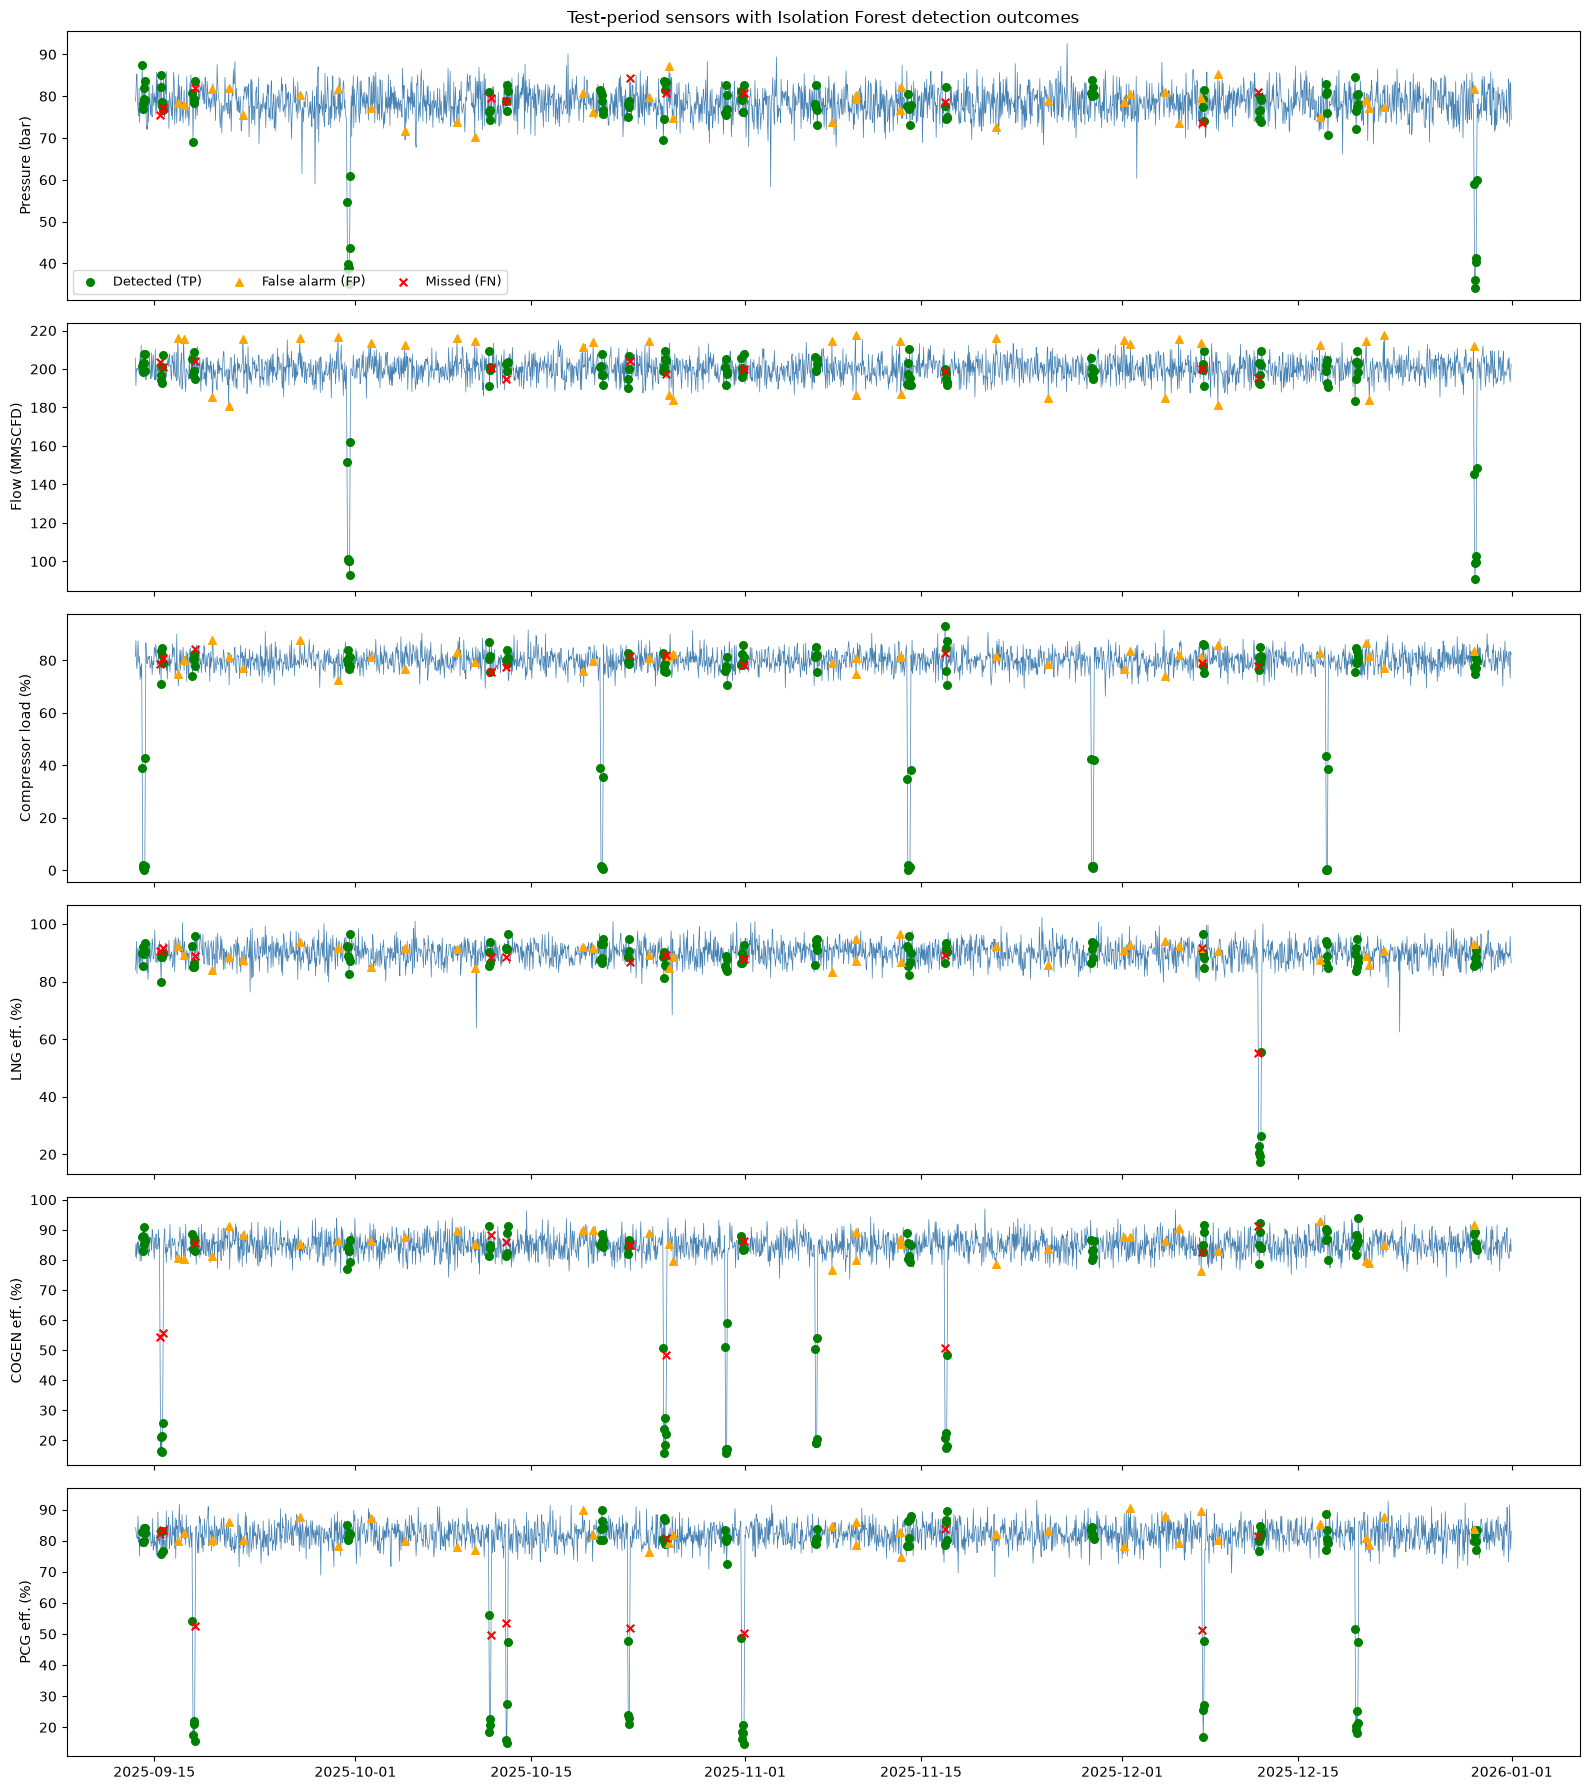

In [14]:
OUTCOME_STYLE = {
    "TP": ("green", "o", "Detected (TP)"),
    "FP": ("orange", "^", "False alarm (FP)"),
    "FN": ("red", "x", "Missed (FN)"),
}


def plot_outcomes(ax, data, column):
    for outcome, (color, marker, label) in OUTCOME_STYLE.items():
        rows = data[data["Detection_Outcome"] == outcome]
        ax.scatter(rows["Timestamp"], rows[column], color=color, marker=marker, s=30, label=label, zorder=3)


sensors = [
    ("Upstream_Pressure", "Pressure (bar)"),
    ("Upstream_Flow", "Flow (MMSCFD)"),
    ("Midstream_Compressor_Load", "Compressor load (%)"),
    ("LNG_Plant_Efficiency", "LNG eff. (%)"),
    ("COGEN_Plant_Efficiency", "COGEN eff. (%)"),
    ("PCG_Plant_Efficiency", "PCG eff. (%)"),
]

fig, axes = plt.subplots(len(sensors), 1, figsize=(16, 3 * len(sensors)), sharex=True)
for ax, (column, ylabel) in zip(axes, sensors):
    ax.plot(df["Timestamp"], df[column], lw=0.5, color="steelblue")
    plot_outcomes(ax, df, column)
    ax.set_ylabel(ylabel)
axes[0].legend(loc="lower left", ncol=3, fontsize=9)
axes[0].set_title("Test-period sensors with Isolation Forest detection outcomes")
plt.tight_layout()
plt.show()

## 4. Isolation Forest anomaly score vs ground truth

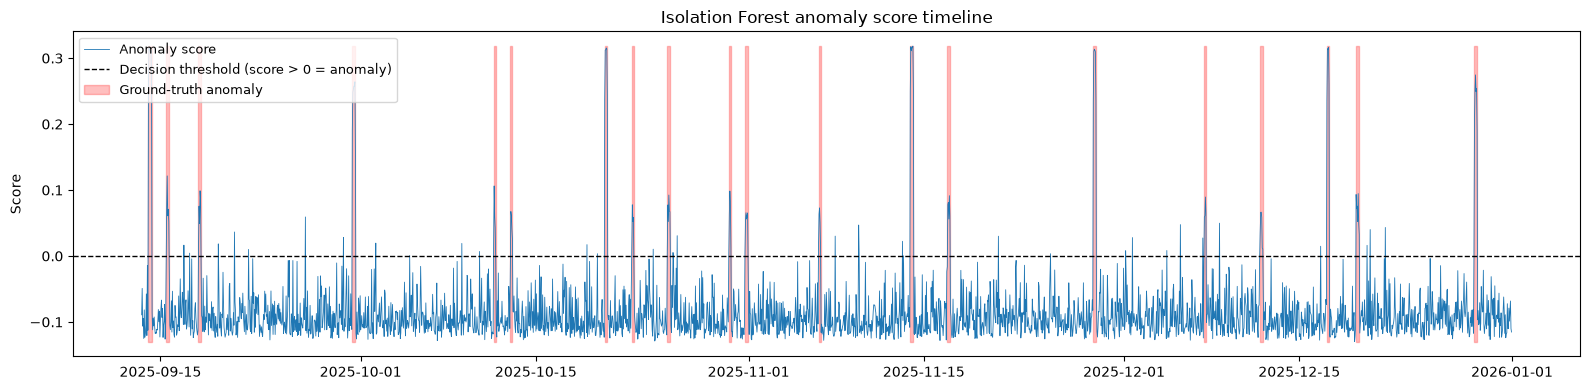

In [15]:
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(df["Timestamp"], df["Anomaly_Score"], lw=0.6, label="Anomaly score")
ax.axhline(0, color="black", ls="--", lw=1, label="Decision threshold (score > 0 = anomaly)")
ax.fill_between(df["Timestamp"], df["Anomaly_Score"].min(), df["Anomaly_Score"].max(),
                where=gt, color="red", alpha=0.25, label="Ground-truth anomaly")
ax.set_ylabel("Score")
ax.set_title("Isolation Forest anomaly score timeline")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 5. ROC curve and confusion matrices

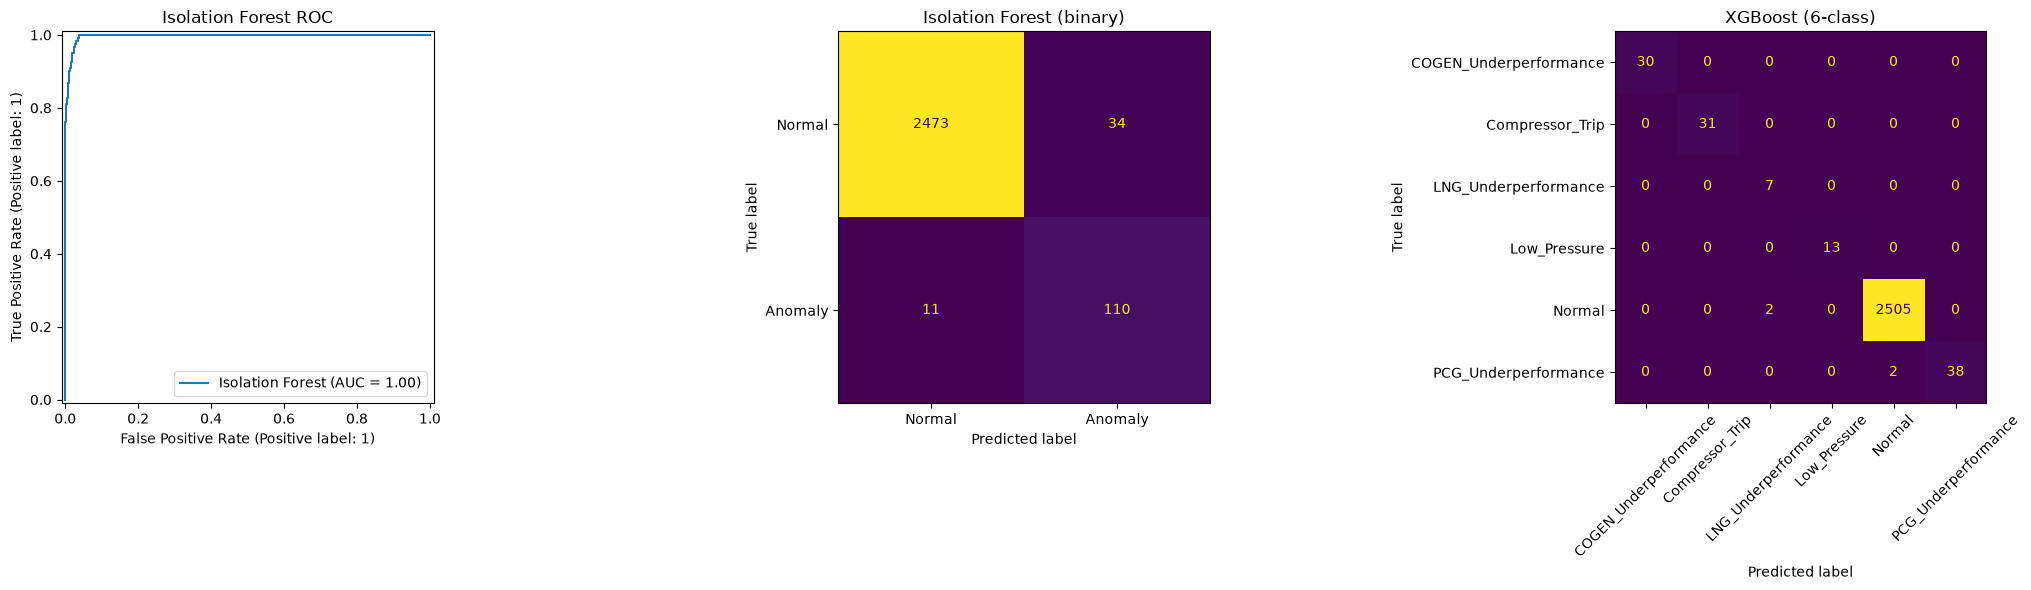

                        precision    recall  f1-score   support

COGEN_Underperformance       1.00      1.00      1.00        30
       Compressor_Trip       1.00      1.00      1.00        31
  LNG_Underperformance       0.78      1.00      0.88         7
          Low_Pressure       1.00      1.00      1.00        13
                Normal       1.00      1.00      1.00      2507
  PCG_Underperformance       1.00      0.95      0.97        40

              accuracy                           1.00      2628
             macro avg       0.96      0.99      0.97      2628
          weighted avg       1.00      1.00      1.00      2628



In [16]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

RocCurveDisplay.from_predictions(df["GroundTruth_Anomaly"], df["Anomaly_Score"],
                                 name="Isolation Forest", ax=axes[0])
axes[0].set_title("Isolation Forest ROC")

ConfusionMatrixDisplay.from_predictions(df["GroundTruth_Anomaly"], df["Predicted_Anomaly"],
                                        display_labels=["Normal", "Anomaly"], ax=axes[1], colorbar=False)
axes[1].set_title("Isolation Forest (binary)")

ConfusionMatrixDisplay.from_predictions(df["System_Status"], df["Predicted_Anomaly_Type"],
                                        ax=axes[2], xticks_rotation=45, colorbar=False)
axes[2].set_title("XGBoost (6-class)")

plt.tight_layout()
plt.show()

print(classification_report(df["System_Status"], df["Predicted_Anomaly_Type"], zero_division=0))

## 6. Zoom on one event per fault type
Shaded = ground-truth event; markers = Isolation Forest outcome; title = XGBoost predictions during the event.

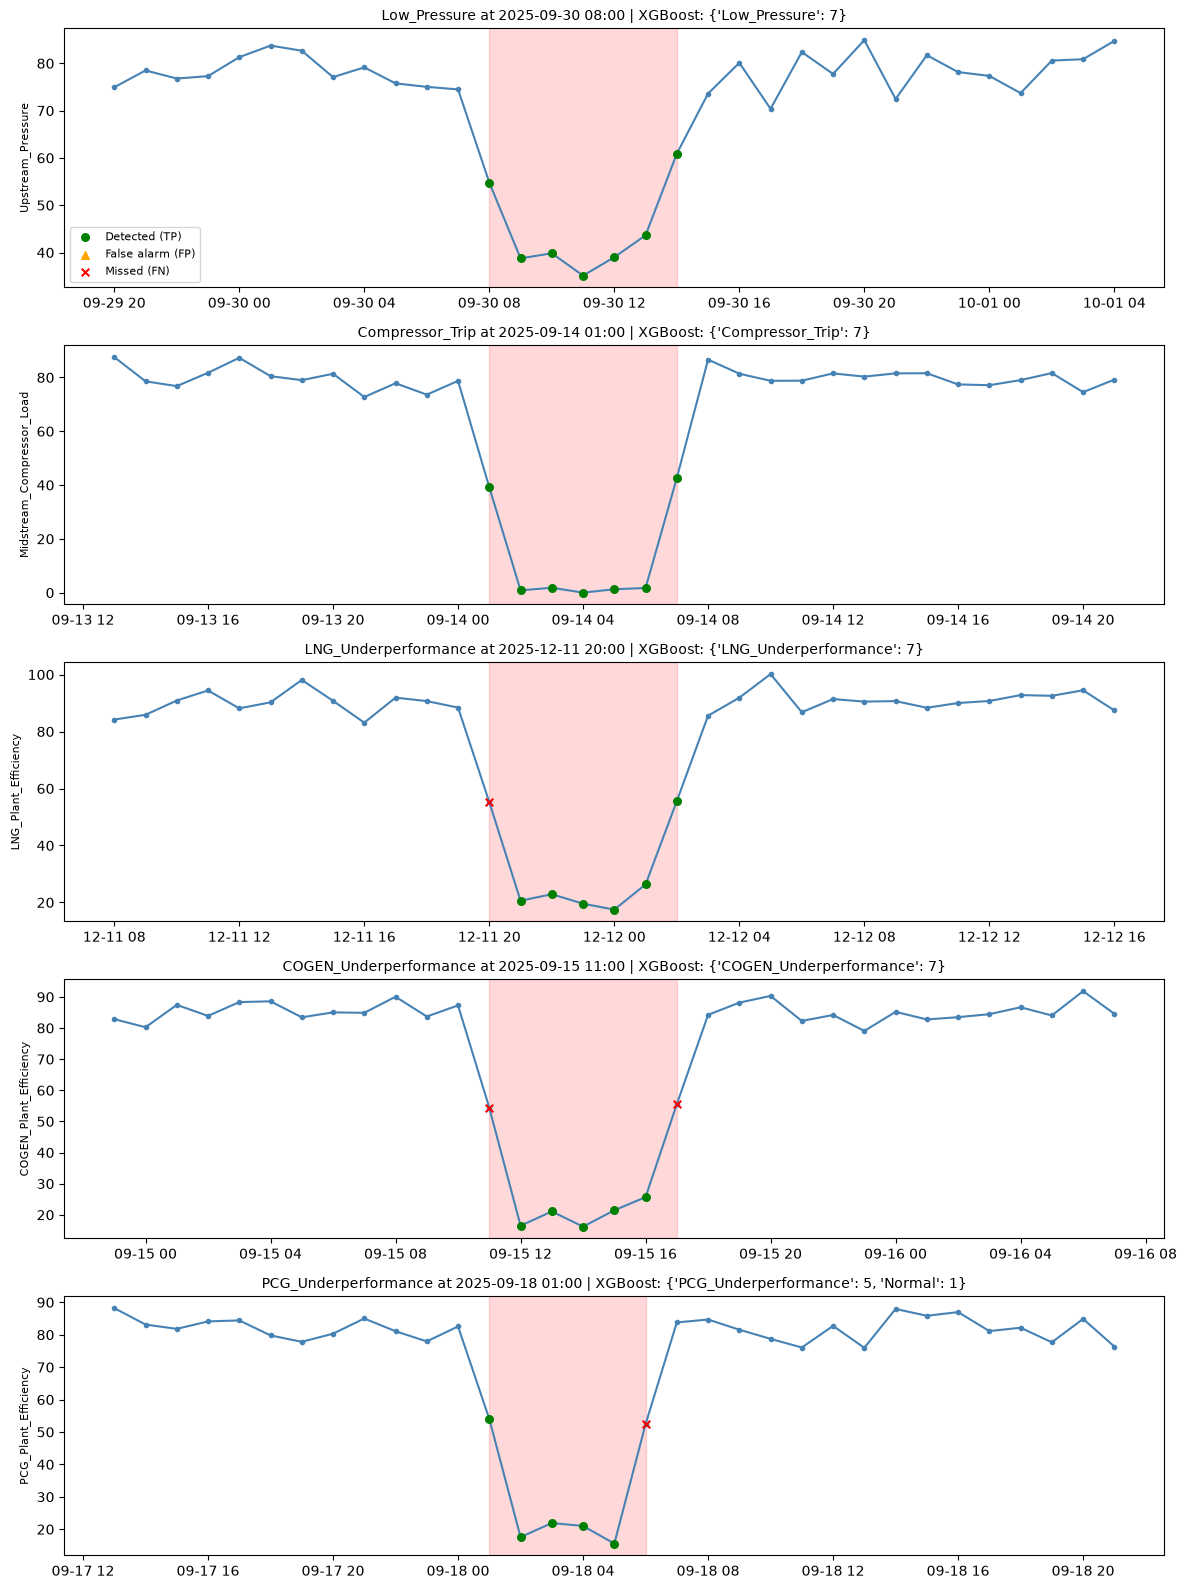

In [17]:
KEY_SENSOR = {
    "Low_Pressure": "Upstream_Pressure",
    "Compressor_Trip": "Midstream_Compressor_Load",
    "LNG_Underperformance": "LNG_Plant_Efficiency",
    "COGEN_Underperformance": "COGEN_Plant_Efficiency",
    "PCG_Underperformance": "PCG_Plant_Efficiency",
}

fig, axes = plt.subplots(len(KEY_SENSOR), 1, figsize=(12, 3.2 * len(KEY_SENSOR)))
for ax, (fault, column) in zip(axes, KEY_SENSOR.items()):
    start = df.index[df["System_Status"] == fault]
    if start.empty:
        ax.set_title(f"{fault}: no event in the test period")
        continue
    # Events are >= 20 h apart, so this window holds exactly one event
    window = df.loc[max(start[0] - 12, 0): start[0] + 20]
    event = window[window["System_Status"] == fault]

    ax.plot(window["Timestamp"], window[column], marker=".", color="steelblue")
    ax.axvspan(event["Timestamp"].min(), event["Timestamp"].max(), color="red", alpha=0.15)
    plot_outcomes(ax, window, column)

    xgb = event["Predicted_Anomaly_Type"].value_counts().to_dict()
    ax.set_title(f"{fault} at {event['Timestamp'].min():%Y-%m-%d %H:%M} | XGBoost: {xgb}", fontsize=10)
    ax.set_ylabel(column, fontsize=8)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

## 7. Missed anomalies and false alarms

In [8]:
cols = ["Timestamp", "System_Status", "Is_Ramp_Hour", "Anomaly_Score", "Predicted_Anomaly_Type",
        "Upstream_Pressure", "Upstream_Flow", "Midstream_Compressor_Load",
        "LNG_Plant_Efficiency", "COGEN_Plant_Efficiency", "PCG_Plant_Efficiency"]

print(f"Missed anomalies (FN): {(df['Detection_Outcome'] == 'FN').sum()}")
display(df.loc[df["Detection_Outcome"] == "FN", cols].round(2))

print(f"False alarms (FP): {(df['Detection_Outcome'] == 'FP').sum()}")
display(df.loc[df["Detection_Outcome"] == "FP", cols].round(2))

Missed anomalies (FN): 11


C:\Users\User\AppData\Local\Temp\ipykernel_41380\1541223391.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df.loc[df["Detection_Outcome"] == "FN", cols].round(2))


,Timestamp,System_Status,Is_Ramp_Hour,Anomaly_Score,Predicted_Anomaly_Type,Upstream_Pressure,Upstream_Flow,Midstream_Compressor_Load,LNG_Plant_Efficiency,COGEN_Plant_Efficiency,PCG_Plant_Efficiency
47,2025-09-15 11:00:00,COGEN_Underperformance,True,-0.02,COGEN_Underperformance,75.56,203.75,78.67,90.56,54.37,82.06
53,2025-09-15 17:00:00,COGEN_Underperformance,True,-0.02,COGEN_Underperformance,77.29,200.87,81.01,91.78,55.54,83.34
114,2025-09-18 06:00:00,PCG_Underperformance,True,-0.02,PCG_Underperformance,81.88,203.96,84.38,89.03,85.51,52.42
679,2025-10-11 19:00:00,PCG_Underperformance,True,-0.01,PCG_Underperformance,79.68,200.27,75.72,88.39,88.41,49.55
707,2025-10-12 23:00:00,PCG_Underperformance,True,-0.03,PCG_Underperformance,78.83,194.87,77.56,88.59,86.01,53.64
944,2025-10-22 20:00:00,PCG_Underperformance,True,-0.01,PCG_Underperformance,84.36,204.35,81.67,86.76,85.09,51.95
1014,2025-10-25 18:00:00,COGEN_Underperformance,True,-0.01,COGEN_Underperformance,80.86,197.50,82.04,89.35,48.41,81.01
1163,2025-10-31 23:00:00,PCG_Underperformance,True,-0.02,PCG_Underperformance,80.72,199.75,78.11,87.74,86.28,50.21
1545,2025-11-16 21:00:00,COGEN_Underperformance,True,-0.02,COGEN_Underperformance,78.55,199.10,82.96,89.24,50.85,83.87
2037,2025-12-07 09:00:00,PCG_Underperformance,True,-0.01,PCG_Underperformance,73.51,200.20,78.93,91.57,82.59,51.17


False alarms (FP): 34


C:\Users\User\AppData\Local\Temp\ipykernel_41380\1541223391.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df.loc[df["Detection_Outcome"] == "FP", cols].round(2))


,Timestamp,System_Status,Is_Ramp_Hour,Anomaly_Score,Predicted_Anomaly_Type,Upstream_Pressure,Upstream_Flow,Midstream_Compressor_Load,LNG_Plant_Efficiency,COGEN_Plant_Efficiency,PCG_Plant_Efficiency
81,2025-09-16 21:00:00,Normal,False,0.02,Normal,78.46,215.94,74.76,92.24,80.52,79.97
92,2025-09-17 08:00:00,Normal,False,0.00,Normal,77.87,215.33,80.18,89.35,80.37,82.57
147,2025-09-19 15:00:00,Normal,False,0.02,Normal,81.66,185.56,87.85,84.20,81.28,80.27
178,2025-09-20 22:00:00,Normal,False,0.04,Normal,82.04,180.58,81.35,88.62,91.14,86.10
205,2025-09-22 01:00:00,Normal,False,0.01,Normal,75.41,215.46,77.06,87.66,88.17,80.29
314,2025-09-26 14:00:00,Normal,False,0.06,Normal,80.28,215.92,87.64,93.79,85.45,87.53
387,2025-09-29 15:00:00,Normal,False,0.03,Normal,81.82,216.42,72.45,91.54,86.44,78.31
449,2025-10-02 05:00:00,Normal,False,0.02,Normal,77.14,213.31,81.26,85.10,86.30,87.44
514,2025-10-04 22:00:00,Normal,False,0.00,Normal,71.57,212.57,76.74,91.84,87.73,79.93
614,2025-10-09 02:00:00,Normal,False,0.02,Normal,73.78,216.04,83.03,91.28,89.61,78.00
